In [7]:
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np
import seaborn as sns

In [8]:
sns.set_theme(style="whitegrid")

In [9]:
df = pd.read_csv(
    "../data/processed/ecommerce_sales_analytics_clean.csv"
)

### 1. Calidad de los Datos

In [10]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 138116 entries, 0 to 138115
Data columns (total 47 columns):
 #   Column                    Non-Null Count   Dtype  
---  ------                    --------------   -----  
 0   order_id                  138116 non-null  object 
 1   order_date                138116 non-null  object 
 2   order_time                138116 non-null  object 
 3   order_status              138116 non-null  object 
 4   sales_channel             138116 non-null  object 
 5   customer_id               138116 non-null  object 
 6   customer_name             138116 non-null  object 
 7   customer_age              138116 non-null  int64  
 8   gender                    138116 non-null  object 
 9   customer_segment          138116 non-null  object 
 10  customer_type             138116 non-null  object 
 11  customer_city             138116 non-null  object 
 12  customer_state            138116 non-null  object 
 13  customer_country          138116 non-null  o

In [11]:
df["order_id"].duplicated().sum()             


np.int64(0)

In [12]:
df.isna().sum()[lambda s: s > 0]

delivery_days               24557
estimated_delivery_days     24557
return_reason              128654
customer_rating             24557
dtype: int64

In [13]:
mask = df["delivery_days"].isna()
print((mask == df["customer_rating"].isna()).all())


True


In [14]:
df[mask]["order_status"].value_counts()

order_status
Returned     9462
Cancelled    8398
Pending      6697
Name: count, dtype: int64

In [15]:
df[mask]["delivery_status"].value_counts()

delivery_status
Cancelled    24557
Name: count, dtype: int64

In [16]:
df[~mask]["order_status"].value_counts()

order_status
Completed    113559
Name: count, dtype: int64

In [17]:

mask = df["delivery_days"].isna()
print((mask == df["customer_rating"].isna()).all())   
df.groupby("return_status")["return_reason"].count()


True


return_status
No Returned       0
Returned       9462
Name: return_reason, dtype: int64

In [18]:
print(df.groupby("order_status")["net_sales"].agg(["count", "sum", "mean"]))


               count           sum        mean
order_status                                  
Cancelled       8398  1.135648e+07  1352.28385
Completed     113559  1.441958e+08  1269.78785
Pending         6697  8.409271e+06  1255.67727
Returned        9462  1.317267e+07  1392.16601


In [19]:
print(df.groupby("currency")["net_sales"].agg(["count", "mean", "median"]))


          count         mean    median
currency                              
AED        4172  1238.248660   926.690
AUD        6794  1297.275612   961.935
CAD        7015  1311.311259   989.990
EUR       11593  1383.953412  1025.100
GBP       20235  1381.922451  1036.380
INR        5707  1352.424615   990.540
USD       82600  1237.652438   915.620


### 2. Estadistica Descriptiva

#### 2.1 Resumen General

In [20]:
df[['net_sales','profit','quantity','customer_age','profit_margin_percentage']].describe()

,net_sales,profit,quantity,customer_age,profit_margin_percentage
count,138116.000000,138116.000000,138116.000000,138116.000000,138116.000000
mean,1282.503575,551.322046,5.615244,45.862681,45.065997
std,1169.274669,516.300936,3.371289,16.467676,13.120357
min,5.800000,-1281.590000,1.000000,18.000000,-59.550000
25%,448.200000,190.757500,3.000000,32.000000,38.880000
50%,950.760000,408.395000,5.000000,46.000000,46.990000
75%,1744.582500,752.845000,8.000000,60.000000,53.770000
max,16218.000000,7083.680000,24.000000,74.000000,77.590000


#### 2.2 Centro de los Datos

In [21]:
df[['net_sales','profit','quantity','customer_age','profit_margin_percentage']].agg(["median","mean"])

,net_sales,profit,quantity,customer_age,profit_margin_percentage
median,950.760000,408.395000,5.000000,46.000000,46.990000
mean,1282.503575,551.322046,5.615244,45.862681,45.065997


In [22]:
columnas = ['net_sales','profit','quantity','customer_age','profit_margin_percentage']

media = df[columnas].mean()
mediana = df[columnas].median()

dif_pct = (media - mediana) / mediana * 100
dif_pct.round(1)

net_sales                   34.9
profit                      35.0
quantity                    12.3
customer_age                -0.3
profit_margin_percentage    -4.1
dtype: float64

#### 2.3 Dispersión

##### A. Desviación Estandar

In [23]:
std = df[columnas].std()
std

net_sales                   1169.274669
profit                       516.300936
quantity                       3.371289
customer_age                  16.467676
profit_margin_percentage      13.120357
dtype: float64

##### B. Coeficiente de Variación

In [24]:
media = df[columnas].mean()
cv = std / media * 100
cv.round(1)

net_sales                   91.2
profit                      93.6
quantity                    60.0
customer_age                35.9
profit_margin_percentage    29.1
dtype: float64

profit	93,6%	Muy dispersa
net_sales	91,2%	Muy dispersa
quantity	60,0%	En el límite de muy dispersa
customer_age	35,9%	Variación considerable
profit_margin_percentage	29,1%	La más pareja

##### C. Quantiles

In [25]:
df[columnas].quantile([0.25, 0.75, 0.95])


,net_sales,profit,quantity,customer_age,profit_margin_percentage
0.25,448.2000,190.7575,3.0,32.0,38.88
0.75,1744.5825,752.8450,8.0,60.0,53.77
0.95,3607.1975,1563.1275,12.0,72.0,62.25


##### D. Maximos y Minimos

In [26]:
df[columnas].max()

net_sales                   16218.00
profit                       7083.68
quantity                       24.00
customer_age                   74.00
profit_margin_percentage       77.59
dtype: float64

In [27]:
df[columnas].min()

net_sales                      5.80
profit                     -1281.59
quantity                       1.00
customer_age                  18.00
profit_margin_percentage     -59.55
dtype: float64

##### 2.4 Perdidas

In [28]:
perdidas = df[df['profit'] < 0]
len(perdidas)
perdidas['order_status'].value_counts()

order_status
Completed    1229
Pending        67
Name: count, dtype: int64

### Conclusion 
Hay 1.296 órdenes con ganancia negativa (0,94%), casi todas Completed (1.229). Ninguna orden cancelada ni devuelta registra pérdida, lo que indica que profit no refleja el costo de esas situaciones.

### 3. Forma de la distribución

In [29]:
df[columnas].skew()

net_sales                   1.903307
profit                      1.983792
quantity                    0.843696
customer_age                0.014573
profit_margin_percentage   -1.369878
dtype: float64

Cómo leer skew() (asimetría)

Entre -0,5 y 0,5	Casi simétrica

Entre 0,5 y 1 (o -1 y -0,5)	Asimetría moderada

Mayor que 1 (o menor que -1)	Asimetría fuerte


In [30]:
df[columnas].kurt()

net_sales                   5.491304
profit                      6.427569
quantity                    0.538819
customer_age               -1.199417
profit_margin_percentage    3.921381
dtype: float64

#### Conclusión
net_sales y profit tienen asimetría positiva fuerte (~1,9-2,0) y colas muy pesadas (curtosis 5,5-6,4): la mayoría de las órdenes son de valor bajo o medio, y unas pocas muy grandes concentran los extremos. El margen tiene asimetría negativa (-1,37) y colas pesadas (3,9) por las órdenes con pérdida. quantity es moderadamente asimétrica (0,84), y customer_age es simétrica y de forma uniforme (curtosis -1,2).

### 4. Visualizaciones

A . Histograma de [net_sales]

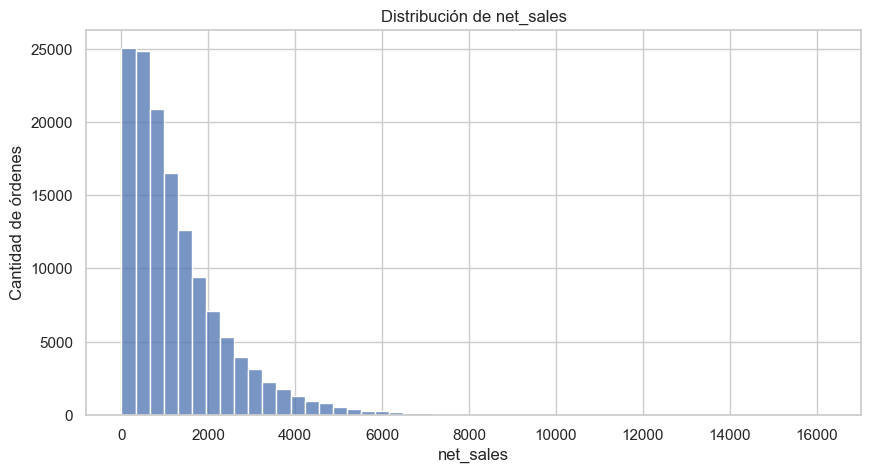

In [31]:
plt.figure(figsize=(10,5))
sns.histplot(df['net_sales'],bins= 50)
plt.title("Distribución de net_sales")
plt.xlabel("net_sales")
plt.ylabel("Cantidad de órdenes")
plt.show()


B . Boxplot Outliers

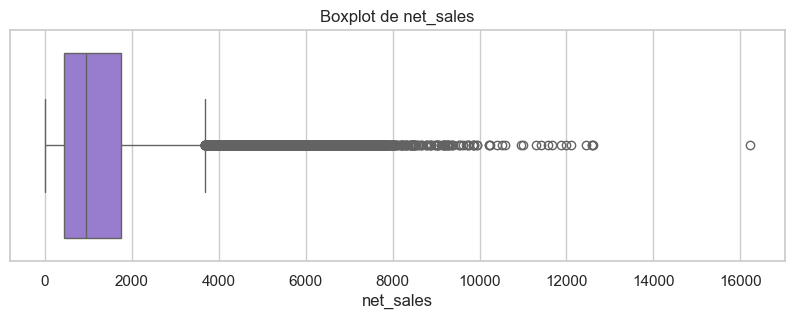

In [32]:
plt.figure(figsize=(10, 3))
sns.boxplot(x=df["net_sales"], color="mediumpurple")
plt.title("Boxplot de net_sales")
plt.xlabel("net_sales")
plt.show()

C. Heatmap de Correlacion

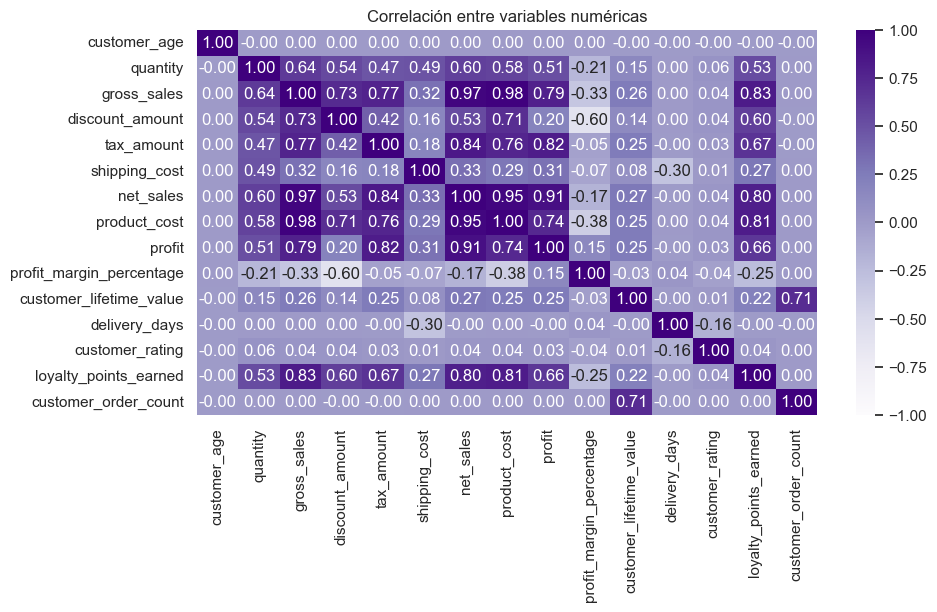

In [33]:
cols = ["customer_age", "quantity", "gross_sales", "discount_amount", "tax_amount",
        "shipping_cost", "net_sales", "product_cost", "profit",
        "profit_margin_percentage", "customer_lifetime_value", "delivery_days",
        "customer_rating", "loyalty_points_earned", "customer_order_count"]

corr = df[cols].corr()

plt.figure(figsize=(10, 5))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="Purples", center=0, vmin=-1, vmax=1)
plt.title("Correlación entre variables numéricas")
plt.show()

D . Heatmap correlacion de canales de ventas

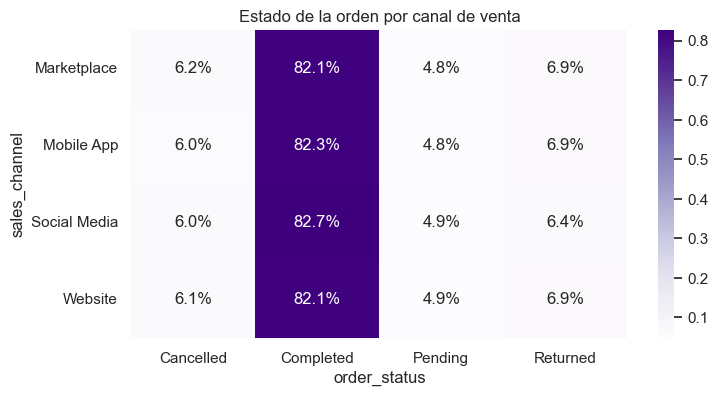

In [34]:
tabla = pd.crosstab(df["sales_channel"], df["order_status"], normalize="index")

plt.figure(figsize=(8, 4))
sns.heatmap(tabla, annot=True, fmt=".1%", cmap="Purples")
plt.title("Estado de la orden por canal de venta")
plt.show()

E . Heatmap por region

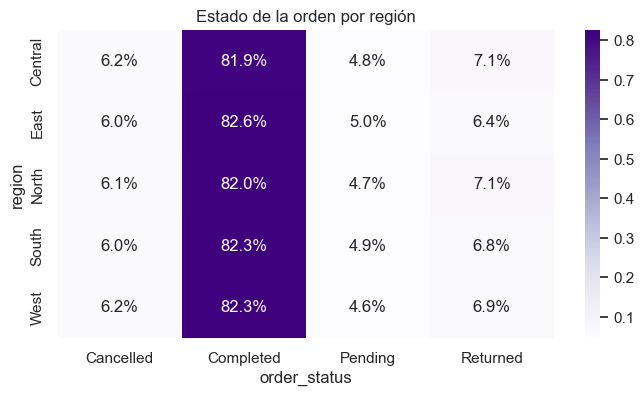

In [35]:
tabla = pd.crosstab(df["region"], df["order_status"], normalize="index")

plt.figure(figsize=(8, 4))
sns.heatmap(tabla, annot=True, fmt=".1%", cmap="Purples")
plt.title("Estado de la orden por región")
plt.show()

F. Ingresos por canal de venta

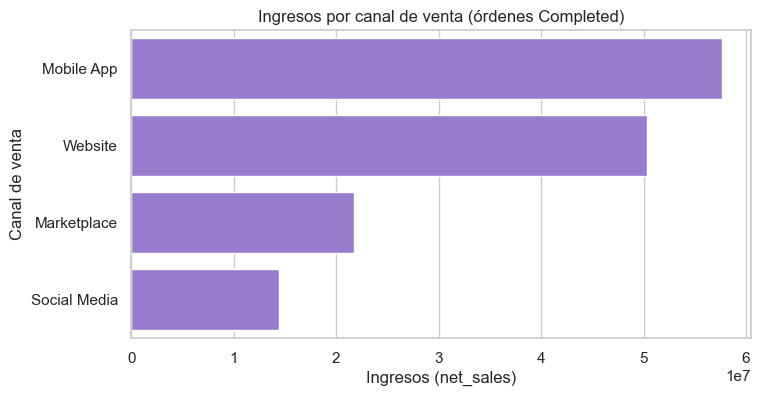

In [36]:
ventas = df[df["order_status"] == "Completed"]
ing_canal = ventas.groupby("sales_channel")["net_sales"].sum().sort_values(ascending=False)

plt.figure(figsize=(8, 4))
sns.barplot(x=ing_canal.values, y=ing_canal.index, color="mediumpurple")
plt.title("Ingresos por canal de venta (órdenes Completed)")
plt.xlabel("Ingresos (net_sales)")
plt.ylabel("Canal de venta")
plt.show()

G. Ingresos por region

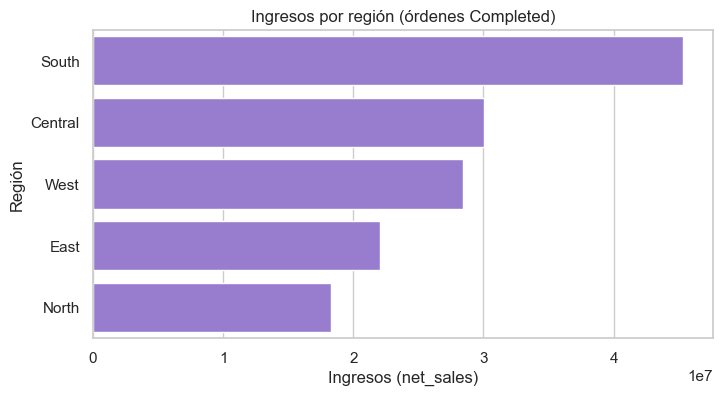

In [37]:
ing_region = ventas.groupby("region")["net_sales"].sum().sort_values(ascending=False)

plt.figure(figsize=(8, 4))
sns.barplot(x=ing_region.values, y=ing_region.index, color="mediumpurple")
plt.title("Ingresos por región (órdenes Completed)")
plt.xlabel("Ingresos (net_sales)")
plt.ylabel("Región")
plt.show()